# NFF5 | Cortney PR2 — Guided, Executable Single-Coil Tutorial
**Purpose:** Produce a reproducible single circular-coil characterization in the SimNIBS `ernie` head model for our left-DLPFC project. **No programming exercises.** Edit the three file paths in Cell 1, then execute the notebook from top to bottom. Read each explanation and verify the printed checkpoints.

**Scientific boundary:** This is an educational proof of concept, not a clinically validated coil design. Cortney generates and exports the standardized idealized 20-mm, single-loop circular coil in this notebook. The model is a preliminary numerical approximation, not a manufactured winding specification. **The FEM run remains subject to Victor's approval.**

## 1 — Connect your files and choose a reproducible output location
**Why:** Reproducibility starts with knowing exactly which head model, generated coil, and output directory produced each result. Edit the **two directory paths** below. The notebook creates the coil itself and saves it under `OUTPUT_DIR / coil / NFF5_CORT_C01.tcd`; do not substitute an older `.tcd` file. This is Cortney's coil-generation deliverable, not a supplied input. The head model must exist before we proceed.

In [1]:
from pathlib import Path
import json, csv, hashlib, datetime
import numpy as np
import matplotlib.pyplot as plt
import simnibs
from simnibs import mesh_io, transformations, sim_struct, run_simnibs
from scipy.spatial import cKDTree
from simnibs.simulation.tms_coil.tms_coil import TmsCoil
from simnibs.simulation.tms_coil.tms_coil_element import LineSegmentElements
from simnibs.simulation.tms_coil.tms_stimulator import TmsStimulator

# ===== EDIT THESE TWO DIRECTORY PATHS ONLY =====
HEAD_DIR = Path(r"C:\Users\cortn\Downloads\simnibs4_examples\m2m_ernie")
COIL_FILE = Path(r"C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_Student\coil\NFF5_CORT_C01.tcd")
OUTPUT_DIR = Path(r"C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs")
# =====================================
TARGET_MNI_MM = np.array([-38., 44., 26.])
ROI_RADIUS_MM = 10.0
NOMINAL_DISTANCE_MM = 3.0
DIDT_A_PER_S = 1.5e8
for label, path in [('ernie mesh', HEAD_DIR/'ernie.msh')]:
    if not path.is_file(): raise FileNotFoundError(f'{label} missing: {path} — correct Cell 1 path and rerun.')
for folder in ('figures','metrics','metadata','fem','coil'):(OUTPUT_DIR/folder).mkdir(parents=True,exist_ok=True)
print('PASS: head model exists | SimNIBS',simnibs.__version__)
print('Head:',HEAD_DIR,'\nCoil will be generated at:',COIL_FILE,'\nOutput:',OUTPUT_DIR)

PASS: head model exists | SimNIBS 4.6.0
Head: C:\Users\cortn\Downloads\simnibs4_examples\m2m_ernie 
Coil will be generated at: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_Student\coil\NFF5_CORT_C01.tcd 
Output: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs


## 2 — Generate, export, and inspect Cortney's circular coil
**Why:** Cortney is responsible for **creating** the computational coil, not merely reading Victor's reference. We approximate a 20-mm-diameter single circular loop with 100 straight wire segments. One hundred distinct perimeter vertices define the circle; repeating the first vertex at the end closes the wire path, so the exported element has **101 stored points representing 100 segments**. This distinction matters for validation.

The model uses an idealized filamentary current path, an assumed `dI/dt`, and a visualization casing; it is **not** a verified physical winding or a clinically validated coil. The Python below is complete. Run it, inspect the geometry plot and printed dimensions, then confirm the saved `.tcd` loads successfully. Do not import the older notebook's output.

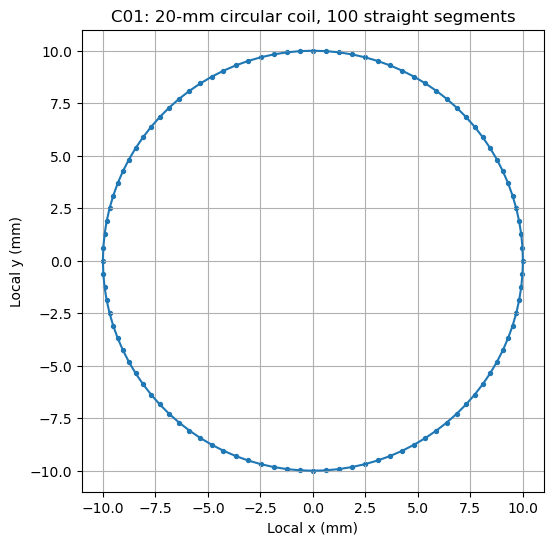

FileExistsError: Coil file already exists: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_Student\coil\NFF5_CORT_C01.tcd. Archive/move it before regenerating.

In [2]:
# Generate the standardized C01 geometry directly in this notebook.
N_SEGMENTS = 100
RADIUS_MM = 10.0
angles = np.linspace(0.0, 2.0*np.pi, N_SEGMENTS, endpoint=False)
vertices_mm = np.column_stack((RADIUS_MM*np.cos(angles),
                               RADIUS_MM*np.sin(angles),
                               np.zeros(N_SEGMENTS)))
closed_vertices_mm = np.vstack((vertices_mm, vertices_mm[0]))
assert vertices_mm.shape == (100, 3)
assert closed_vertices_mm.shape == (101, 3)
assert np.allclose(np.linalg.norm(vertices_mm[:, :2], axis=1), RADIUS_MM)
assert np.allclose(closed_vertices_mm[0], closed_vertices_mm[-1])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(closed_vertices_mm[:, 0], closed_vertices_mm[:, 1], '-', lw=1.5)
ax.scatter(vertices_mm[:, 0], vertices_mm[:, 1], s=8)
ax.set(aspect='equal', xlabel='Local x (mm)', ylabel='Local y (mm)',
       title='C01: 20-mm circular coil, 100 straight segments')
ax.grid(True)
fig.savefig(OUTPUT_DIR/'figures'/'C01_generated_geometry.png', dpi=180, bbox_inches='tight')
plt.show()

# SimNIBS 4.6 line-element construction, following the working geometry workflow.
stimulator = TmsStimulator('NFF5 PR2 Stimulator', 'NFF5', DIDT_A_PER_S)
line_element = LineSegmentElements(stimulator, closed_vertices_mm,
                                   name='20-mm Circular Coil')
generated_coil = TmsCoil([line_element], 'NFF5 20-mm Circular Coil',
                         'NFF5', 'PR2-v1',
                         [[-50., 50.], [-50., 50.], [-50., 50.]],
                         [1., 1., 1.])
generated_coil.generate_element_casings(2.0, 1.0, False)

# Refuse to silently overwrite a previously generated coil. Archive or move it
# before deliberately regenerating, then rerun this cell.
if COIL_FILE.exists():
    raise FileExistsError(f'Coil file already exists: {COIL_FILE}. Archive/move it before regenerating.')
generated_coil.write(str(COIL_FILE))
print('GENERATED:', COIL_FILE)
print('Diameter (mm):', 2*RADIUS_MM, '| segments:', N_SEGMENTS,
      '| stored path points:', len(closed_vertices_mm))

# Independently reload the file that the later FEM session will actually use.
coil = TmsCoil.from_file(str(COIL_FILE))
assert len(coil.elements) == 1, f'Expected one coil element, got {len(coil.elements)}'
assert len(coil.elements[0].points) == 101, (
    f'Expected 101 stored points (100 closed segments), got {len(coil.elements[0].points)}')
assert np.isclose(coil.elements[0].stimulator.max_di_dt, DIDT_A_PER_S), 'Drive mismatch.'
coil_hash = hashlib.sha256(COIL_FILE.read_bytes()).hexdigest()
print('PASS: generated .tcd reloaded and validated')
print('SHA-256:', coil_hash)
print('Maximum dI/dt (A/s):', coil.elements[0].stimulator.max_di_dt)


## 3 — Locate the DLPFC target in the subject's anatomy
**Why:** Our published target coordinate is in MNI space, but the `ernie` mesh uses subject coordinates. Directly treating MNI coordinates as mesh coordinates would move the target. We transform it and find a nearby scalp vertex, then visualize the target and scalp surface as a placement sanity check. The scalp vertex is a **starting location**, not proof of wire clearance.

MNI target: [-38.  44.  26.] 
Ernie target: [-33.71   70.748  43.765] 
Nearest scalp vertex: [-47.066  82.069  52.255]


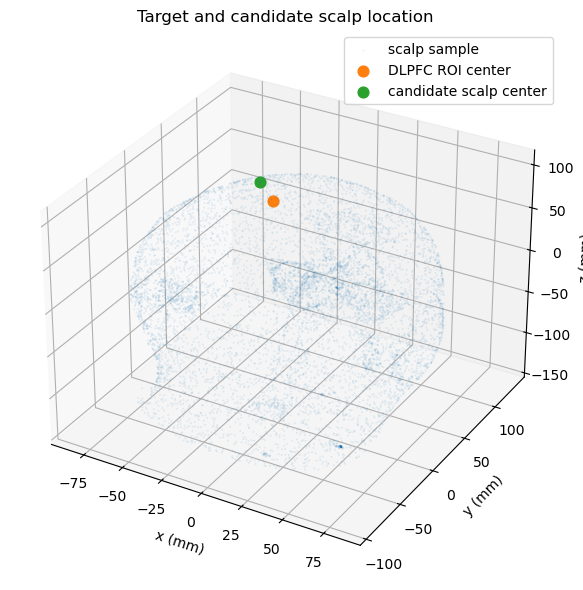

CHECK: target and scalp center should appear anatomically plausible.


In [3]:
target_subject=np.asarray(transformations.mni2subject_coords(TARGET_MNI_MM.reshape(1,3),str(HEAD_DIR)),float).reshape(3)
head_mesh=mesh_io.read_msh(str(HEAD_DIR/'ernie.msh'))
mask=(np.asarray(head_mesh.elm.tag1)==1005)&(np.asarray(head_mesh.elm.elm_type)==2)
tri=np.asarray(head_mesh.elm.node_number_list[mask,:3],int)
assert len(tri)>0,'No scalp triangles (tag 1005) found: ask Victor to inspect mesh.'
scalp=np.asarray(head_mesh.nodes.node_coord[np.unique(tri)-1],float)
_,idx=cKDTree(scalp).query(target_subject)
center=scalp[idx]
print('MNI target:',TARGET_MNI_MM,'\nErnie target:',np.round(target_subject,3),'\nNearest scalp vertex:',np.round(center,3))
fig=plt.figure(figsize=(8,6));ax=fig.add_subplot(111,projection='3d')
step=max(1,len(scalp)//8000)
ax.scatter(*scalp[::step].T,s=0.15,alpha=.12,label='scalp sample')
ax.scatter(*target_subject,s=60,label='DLPFC ROI center');ax.scatter(*center,s=60,label='candidate scalp center')
ax.set(xlabel='x (mm)',ylabel='y (mm)',zlabel='z (mm)',title='Target and candidate scalp location');ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'figures'/'target_and_scalp.png',dpi=180);plt.show()
print('CHECK: target and scalp center should appear anatomically plausible.')

## 4 — Establish a reproducible coil orientation
**Why:** A coil position requires both a center and an orientation. We estimate an outward scalp normal from nearby scalp points, orient it away from the head interior, and choose a tangent-plane direction. This is an automated **candidate** orientation, not a full anatomical optimization. Review the printed values and image with Victor before FEM.

Candidate center: [-47.066  82.069  52.255] 
Outward normal: [-0.6911  0.5523  0.4663] 
Tangent direction: [ 0.3642 -0.2911  0.8847]
Nominal SimNIBS placement distance: 3.0 mm (NOT measured wire-to-scalp clearance)


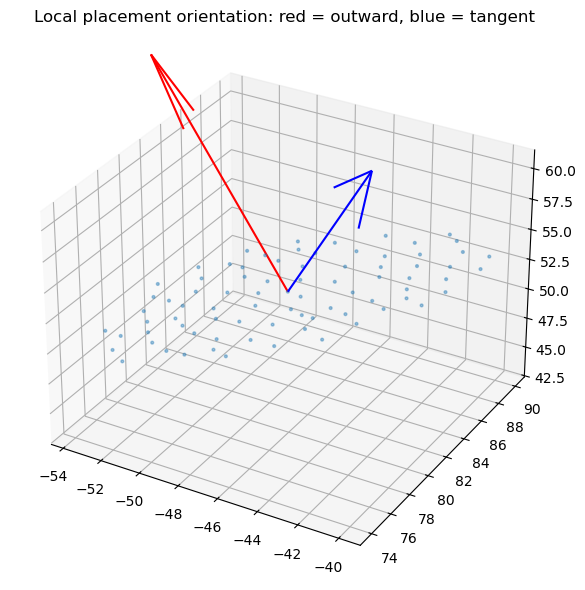

In [4]:
tree=cKDTree(scalp);_,neighbor_ids=tree.query(center,k=min(80,len(scalp)))
near=scalp[np.atleast_1d(neighbor_ids)];_,_,vh=np.linalg.svd(near-near.mean(axis=0),full_matrices=False)
normal=vh[-1];interior=np.asarray(head_mesh.nodes.node_coord,float).mean(axis=0)
if np.dot(normal,center-interior)<0:normal=-normal
ref=np.array([0.,0.,1.]);ref=np.array([0.,1.,0.]) if abs(np.dot(ref,normal))>.95 else ref
ydir=ref-np.dot(ref,normal)*normal;ydir/=np.linalg.norm(ydir)
orientation_point=center+20*ydir
assert abs(np.dot(ydir,normal))<1e-6
print('Candidate center:',np.round(center,3),'\nOutward normal:',np.round(normal,4),'\nTangent direction:',np.round(ydir,4))
print('Nominal SimNIBS placement distance:',NOMINAL_DISTANCE_MM,'mm (NOT measured wire-to-scalp clearance)')
fig=plt.figure(figsize=(7,6));ax=fig.add_subplot(111,projection='3d');ax.scatter(*near.T,s=4,alpha=.4)
ax.quiver(*center,*normal,length=18,color='red');ax.quiver(*center,*ydir,length=18,color='blue')
ax.set_title('Local placement orientation: red = outward, blue = tangent');plt.tight_layout()
plt.savefig(OUTPUT_DIR/'figures'/'placement_orientation.png',dpi=180);plt.show()

## 5 — Stage the FEM and request approval (STOP POINT)
**Why:** FEM runs are expensive, and an incorrect coil orientation or mesh choice can waste hours. This cell **prepares** the SimNIBS session but does not run it. Send Victor the target/scalp figure, orientation figure, and the printed parameters. **Wait for explicit approval.** Nominal `distance=3 mm` is not a measured minimum distance between every wire segment and the scalp; that physical-clearance check requires separate verification.

In [6]:
session=sim_struct.SESSION();session.subpath=str(HEAD_DIR)
FEM_DIR=OUTPUT_DIR/'fem'/'C01'
session.pathfem=str(FEM_DIR);session.open_in_gmsh=False
stim=session.add_tmslist();stim.fnamecoil=str(COIL_FILE)
position=stim.add_position();position.centre=center.tolist();position.pos_ydir=orientation_point.tolist()
position.distance=NOMINAL_DISTANCE_MM;position.didt=DIDT_A_PER_S
session.fields='eE'  # element magnitude plus vector for later reuse, if supported by installed SimNIBS
coil_hash = hashlib.sha256(COIL_FILE.read_bytes()).hexdigest()
approval_packet={'coil_file':str(COIL_FILE),'coil_sha256':coil_hash,'head_dir':str(HEAD_DIR),'target_mni_mm':TARGET_MNI_MM.tolist(),'target_subject_mm':target_subject.tolist(),'scalp_center_mm':center.tolist(),'orientation_point_mm':orientation_point.tolist(),'outward_normal':normal.tolist(),'nominal_distance_mm':NOMINAL_DISTANCE_MM,'didt_A_per_s':DIDT_A_PER_S,'fem_output_dir':str(FEM_DIR),'status':'AWAITING_VICTOR_APPROVAL'}
(OUTPUT_DIR/'metadata'/'approval_packet.json').write_text(json.dumps(approval_packet,indent=2))
print('STOP: FEM NOT RUN. Send Victor both figures and metadata/approval_packet.json.')
print('Planned FEM folder:',FEM_DIR)

STOP: FEM NOT RUN. Send Victor both figures and metadata/approval_packet.json.
Planned FEM folder: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs\fem\C01


## 6 — Run the approved FEM (one explicit switch)
**Why:** Once Victor has reviewed the setup, this cell solves the electromagnetic problem. It is intentionally disabled by default. After approval, change `APPROVED_TO_RUN` to `True` and run this cell. The code refuses to overwrite an existing FEM directory. If a result already exists, leave the switch off and continue to analysis.

In [7]:
APPROVED_TO_RUN = True  # Change ONLY after Victor explicitly approves.
if not APPROVED_TO_RUN:
    print('FEM SKIPPED. Approval is required. Continue with the independent synthetic verification in Section 8.')
else:
    if FEM_DIR.exists() and any(FEM_DIR.iterdir()):
        raise FileExistsError(f'Refusing to overwrite nonempty FEM folder: {FEM_DIR}')
    assert (OUTPUT_DIR/'metadata'/'approval_packet.json').is_file()
    print('Starting approved SimNIBS FEM; this may take time...')
    run_simnibs(session)
    print('FEM complete. Next inspect the saved result mesh.')

[ simnibs ] INFO: Head Mesh:          C:\Users\cortn\Downloads\simnibs4_examples\m2m_ernie\ernie.msh
[ simnibs ] INFO: Subject Path:       C:\Users\cortn\Downloads\simnibs4_examples\m2m_ernie
[ simnibs ] INFO: Simulation Folder:  C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs\fem\C01


Starting approved SimNIBS FEM; this may take time...


[ simnibs ] INFO: Running simulations in the directory: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs\fem\C01
[ simnibs ] INFO: Running Poslist Number: 1
[ simnibs ] INFO: Began to run TMS simulations
[ simnibs ] INFO: Coil file: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_Student\coil\NFF5_CORT_C01.tcd
[ simnibs ] INFO: Using isotropic conductivities
[ simnibs ] INFO: Calculating Coil position from (centre, pos_y, distance)
[ simnibs ] INFO: matsimnibs: 
[[ 6.3590e-01  3.6374e-01  6.8068e-01 -4.9108e+01]
 [ 7.7173e-01 -2.9068e-01 -5.6563e-01  8.3766e+01]
 [-7.8837e-03  8.8499e-01 -4.6555e-01  5.3651e+01]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]
[ simnibs ] INFO: coil-cortex distance: 16.17mm
[ simnibs ] INFO: Assembling FEM Matrix
[ simnibs ] INFO: 12.60 s to assemble FEM matrix
[ simnibs ] INFO: Calculating dA/dt field
[ simnibs ] INFO: 2.55s to calculate dA/dt
[ simnibs ] INFO: Using solver options: hypre
[ simnibs ] I

FEM complete. Next inspect the saved result mesh.


## 7 — Read the saved FEM and compute the volume-weighted target metric
**Why:** The mean electric field inside the DLPFC should reflect tissue **volume**, not the number of mesh elements. We select gray-matter tetrahedra (tag 2) whose centroids fall inside a 10-mm sphere around the subject-space target. Each tetrahedron contributes in proportion to its physical volume. We also save an auditable CSV. If FEM has not run yet, the cell reports **PENDING**, not a made-up result.

In [8]:
def roi_from_mesh(mesh,center_mm,radius_mm=10.,gm_tag=2):
    fields={f.field_name:np.asarray(f.value) for f in mesh.elmdata}
    if 'magnE' in fields: magn=np.asarray(fields['magnE'],float).reshape(-1)
    elif 'E' in fields and fields['E'].ndim==2 and fields['E'].shape[1]==3: magn=np.linalg.norm(fields['E'],axis=1)
    else: raise KeyError(f'Need element magnE or 3-component E; available fields: {list(fields)}')
    elm=mesh.elm; gm=(np.asarray(elm.tag1)==gm_tag)&(np.asarray(elm.elm_type)==4)
    xyz=np.asarray(mesh.nodes.node_coord[elm.node_number_list[gm,:4]-1],float)
    centers=xyz.mean(axis=1);keep=np.linalg.norm(centers-center_mm,axis=1)<=radius_mm
    if not keep.any():raise ValueError('No gray matter tetrahedra in the target ROI')
    t=xyz[keep];vol=np.abs(np.einsum('ij,ij->i',t[:,1]-t[:,0],np.cross(t[:,2]-t[:,0],t[:,3]-t[:,0])))/6
    e=magn[gm][keep]
    assert np.all(np.isfinite(e)) and np.all(vol>0),'Invalid fields or volumes'
    return {'mean_E_V_per_m':float(np.average(e,weights=vol)),'roi_volume_mm3':float(vol.sum()),'roi_tetrahedra':int(len(e)),'min_E_V_per_m':float(e.min()),'max_E_V_per_m':float(e.max())}

result_files=sorted(FEM_DIR.rglob('*.msh')) if FEM_DIR.exists() else []
metrics=None
if not result_files:print('PENDING: No FEM mesh yet. This is expected before approval.')
elif len(result_files)!=1:print('ACTION REQUIRED: Multiple result meshes found; ask Victor which one is authoritative:',result_files)
else:
    result_mesh=mesh_io.read_msh(str(result_files[0]));metrics=roi_from_mesh(result_mesh,target_subject,ROI_RADIUS_MM)
    print('PASS: FEM ROI analysis:',metrics)
    with (OUTPUT_DIR/'metrics'/'C01_target_roi.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=['mesh_path',*metrics.keys()]);writer.writeheader();writer.writerow({'mesh_path':str(result_files[0]),**metrics})
    print('Saved:',OUTPUT_DIR/'metrics'/'C01_target_roi.csv')

PASS: FEM ROI analysis: {'mean_E_V_per_m': 1.8090731174779953, 'roi_volume_mm3': 1983.9868901771138, 'roi_tetrahedra': 4091, 'min_E_V_per_m': 0.06830175751400401, 'max_E_V_per_m': 5.3247380220478995}
Saved: C:\Users\cortn\OneDrive\Desktop\Capstone class\NFF5_Cortney_PR2_REVISED_outputs\metrics\C01_target_roi.csv


## 8 — Independent numerical verification (works before FEM)
**Why:** Before trusting a complicated anatomical result, we test the exact same ROI calculation on a tiny synthetic mesh with a known answer. This confirms that tetrahedron volumes, gray-matter selection, and field averaging are behaving correctly. **Run this while waiting for approval**; no SimNIBS solve is needed.

In [9]:
# Pure numerical check of the volume-weighting formula used above.
def weighted_mean(values,volumes):
    values=np.asarray(values,float);volumes=np.asarray(volumes,float)
    assert len(values)==len(volumes) and len(values)>0 and np.all(volumes>0)
    return float(np.average(values,weights=volumes))
assert np.isclose(weighted_mean([10,10],[1,3]),10)
assert np.isclose(weighted_mean([10,30],[1,3]),25)
assert not np.isclose(weighted_mean([10,30],[1,3]),20)
# Verify physical tetrahedron volume on a unit tetrahedron.
t=np.array([[0,0,0],[1,0,0],[0,1,0],[0,0,1]],float)
vol=abs(np.dot(t[1]-t[0],np.cross(t[2]-t[0],t[3]-t[0])))/6
assert np.isclose(vol,1/6)
print('PASS: uniform field, unequal-volume weighted mean, and unit-tetrahedron volume tests.')

PASS: uniform field, unequal-volume weighted mean, and unit-tetrahedron volume tests.


## 9 — Export a concise, meeting-ready summary
**Why:** A reproducible notebook is most useful when another team member can quickly identify what was modeled, what was measured, and what remains unverified. This cell writes a short summary you can use for Friday's meeting and the PR2 report. **No separate formal paper is required.** Replace the bracketed interpretation with your own observations after you review the figures and outputs.

In [10]:
status='FEM complete and ROI analyzed' if metrics is not None else 'FEM pending approval or output review'
summary=f'''# Cortney PR2 — Single-Coil Tutorial Summary

- Head model: ernie (SimNIBS {simnibs.__version__})
- Coil: {COIL_FILE.name} (SHA-256: {coil_hash})
- Target: MNI {TARGET_MNI_MM.tolist()} → ernie {np.round(target_subject,3).tolist()} mm
- Target ROI: gray matter, 10-mm radius, tetrahedron-centroid selection
- FEM setup: nominal placement distance {NOMINAL_DISTANCE_MM} mm; dI/dt {DIDT_A_PER_S:.3g} A/s
- Status: {status}
- Target ROI results: {json.dumps(metrics) if metrics is not None else 'PENDING — no invented result'}
- Verification: weighted-average and tetrahedron-volume synthetic tests passed
- Method limitation: nominal coil distance does not prove minimum physical wire-to-scalp clearance.
- Interpretation to discuss Friday: [What do the verified results imply? What remains to be checked?]
- Research source for coil geometry: [Insert verified citation from your research]
'''
summary_path=OUTPUT_DIR/'metadata'/'Cortney_PR2_summary.md';summary_path.write_text(summary,encoding='utf-8')
print(summary);print('Saved summary:',summary_path)

# Cortney PR2 — Single-Coil Tutorial Summary

- Head model: ernie (SimNIBS 4.6.0)
- Coil: NFF5_CORT_C01.tcd (SHA-256: d08e6ac39cb504c69a1ce1a5f4cf812f96009f7aba8d752b105f92c2ed527211)
- Target: MNI [-38.0, 44.0, 26.0] → ernie [-33.71, 70.748, 43.765] mm
- Target ROI: gray matter, 10-mm radius, tetrahedron-centroid selection
- FEM setup: nominal placement distance 3.0 mm; dI/dt 1.5e+08 A/s
- Status: FEM complete and ROI analyzed
- Target ROI results: {"mean_E_V_per_m": 1.8090731174779953, "roi_volume_mm3": 1983.9868901771138, "roi_tetrahedra": 4091, "min_E_V_per_m": 0.06830175751400401, "max_E_V_per_m": 5.3247380220478995}
- Verification: weighted-average and tetrahedron-volume synthetic tests passed
- Method limitation: nominal coil distance does not prove minimum physical wire-to-scalp clearance.
- Interpretation to discuss Friday: [What do the verified results imply? What remains to be checked?]
- Research source for coil geometry: [Insert verified citation from your research]

Saved

## Final verification checklist
- [ ] Head-model path exists; coil was generated in Section 2 (not supplied or substituted).
- [ ] Generated coil model is a single 100-point element; SHA-256 recorded.
- [ ] MNI target transformed into `ernie` coordinates; placement plot inspected.
- [ ] Candidate orientation reviewed and **Victor explicitly approved** the FEM before running.
- [ ] If approved, FEM result mesh is present and ROI CSV was exported.
- [ ] Synthetic numerical tests pass even if FEM is pending.
- [ ] Meeting summary identifies methods, measured results, limitations, and outstanding issues.

**For Friday:** Show your notebook, target/placement images, approval status, ROI metric if available, and one-minute explanation of what you verified. This is a guided educational tutorial; there are no code-writing assignments.